Original Dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dataset Shape: (150, 4)

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Dataset After K-Means Clustering:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6        

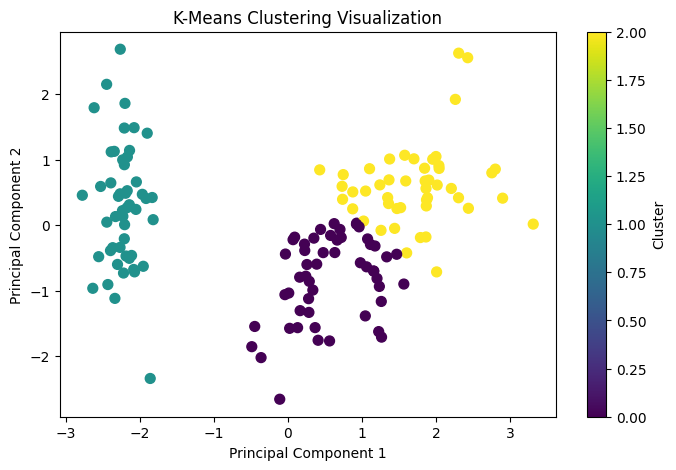

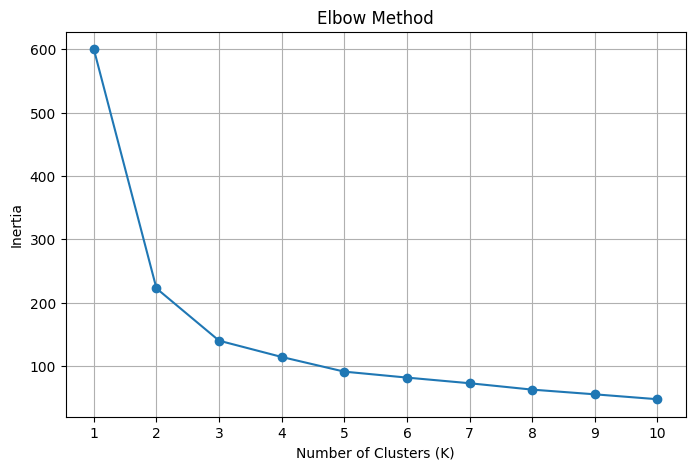


FINAL RESULT
K-Means Clustering Completed Successfully!
Total Clusters: 3
Total Data Points: 150
Silhouette Score: 0.4599


In [1]:

# K-MEANS CLUSTERING ON AN UNSUPERVISED DATASET

# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Load dataset (without using target labels)
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)

print("Original Dataset:")
print(X.head())

print("\nDataset Shape:", X.shape)

# Check missing values
print("\nMissing Values:")
print(X.isnull().sum())

# Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Add cluster labels to dataset
X['Cluster'] = clusters

# Display clustered dataset
print("\nDataset After K-Means Clustering:")
print(X.head(10))

# Display number of data points in each cluster
print("\nCluster Distribution:")
print(X['Cluster'].value_counts())

# Calculate Silhouette Score
score = silhouette_score(X_scaled, clusters)
print("\nSilhouette Score:", round(score, 4))

# Display cluster centers
print("\nCluster Centers:")
print(scaler.inverse_transform(kmeans.cluster_centers_))

# Visualize clusters using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c=clusters, cmap='viridis', s=50)

plt.title("K-Means Clustering Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

# Elbow Method to find optimal K
inertia = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid()
plt.show()

# Final Result
print("\nFINAL RESULT")
print("K-Means Clustering Completed Successfully!")
print("Total Clusters:", len(set(clusters)))
print("Total Data Points:", len(X))
print("Silhouette Score:", round(score, 4))

Original Dataset:
   CustomerID  Age  Annual Income (k$)  Spending Score (1-100)
0           1   56                  84                      61
1           2   69                  86                      48
2           3   46                  41                      19
3           4   32                  23                       4
4           5   60                  76                      35

Dataset Shape: (200, 4)

Clustered Dataset:
   CustomerID  Age  Annual Income (k$)  Spending Score (1-100)  Cluster
0           1   56                  84                      61        4
1           2   69                  86                      48        0
2           3   46                  41                      19        2
3           4   32                  23                       4        2
4           5   60                  76                      35        0
5           6   25                  51                      64        1
6           7   38                 111                 

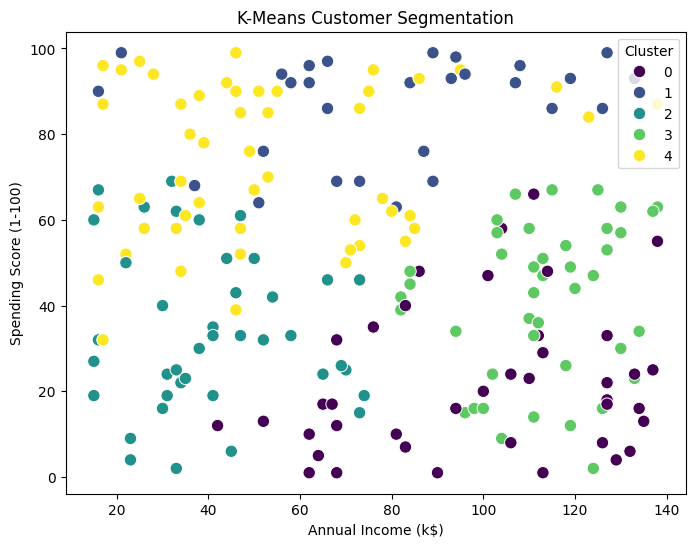

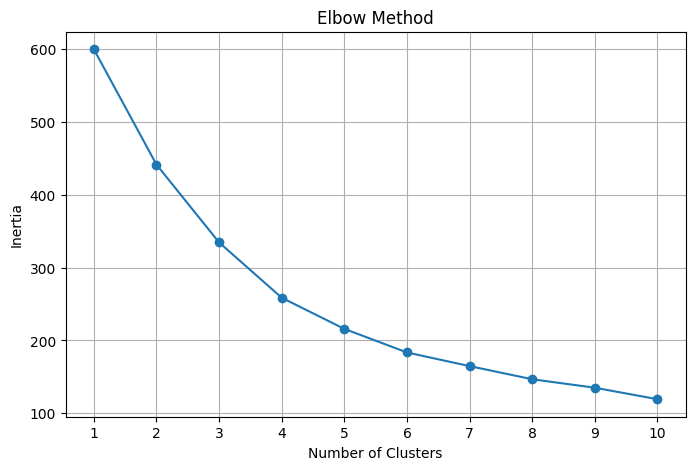


FINAL RESULT
K-Means Clustering Completed Successfully!
Total Customers: 200
Total Clusters: 5
Silhouette Score: 0.3052


In [2]:

# K-MEANS CLUSTERING USING MALL CUSTOMERS DATASET

# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Create Mall Customers Dataset
np.random.seed(42)

data = {
    'CustomerID': range(1, 201),
    'Age': np.random.randint(18, 70, 200),
    'Annual Income (k$)': np.random.randint(15, 140, 200),
    'Spending Score (1-100)': np.random.randint(1, 100, 200)
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

# Select features for clustering
X = df[['Age', 'Annual Income (k$)',
        'Spending Score (1-100)']]

# Standardize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means Clustering
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Display clustered dataset
print("\nClustered Dataset:")
print(df.head(10))

# Display cluster distribution
print("\nNumber of Customers in Each Cluster:")
print(df['Cluster'].value_counts().sort_index())

# Calculate Silhouette Score
score = silhouette_score(X_scaled, df['Cluster'])
print("\nSilhouette Score:", round(score, 4))

# Display cluster centers
centers = scaler.inverse_transform(kmeans.cluster_centers_)
print("\nCluster Centers:")
print(pd.DataFrame(centers, columns=X.columns))

# Visualize clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='viridis',
    s=80
)
plt.title("K-Means Customer Segmentation")
plt.show()

# Elbow Method
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid()
plt.show()

# Final Result
print("\nFINAL RESULT")
print("K-Means Clustering Completed Successfully!")
print("Total Customers:", len(df))
print("Total Clusters:", df['Cluster'].nunique())
print("Silhouette Score:", round(score, 4))